Part h and i

Optimal k values: [1, 3, 7]


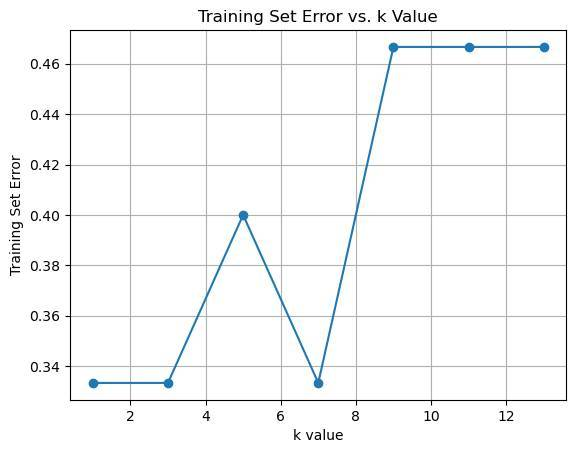

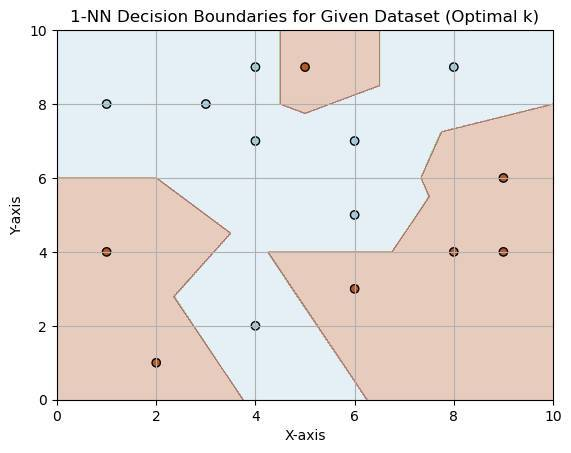

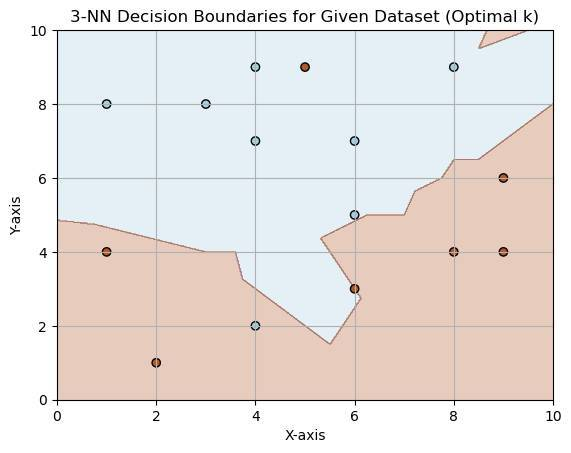

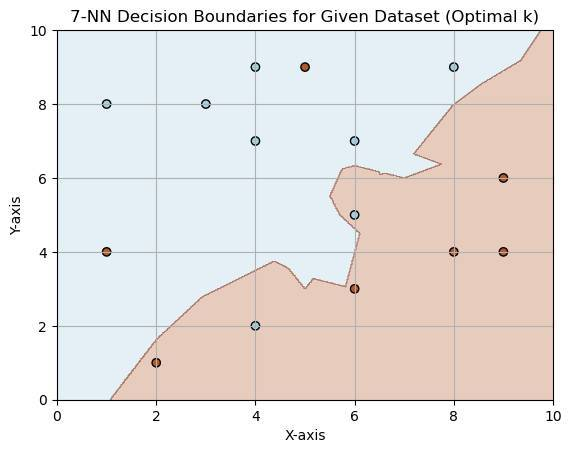

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Given data points from the question file
X = np.array([[2, 1], [1, 4], [1, 8], [3, 8], [4, 2], [4, 7], [4, 9], [5, 9], [6, 3], [6, 5], [6, 7], [8, 4], [8, 9], [9, 4], [9, 6]])
y = np.array([2, 2, 1, 1, 1, 1, 1, 2, 2, 1, 1, 2, 1, 2, 2])  # Classes for the points (+ = 1, - = 2)

# Creating a mesh to plot the decision boundaries
x_min, x_max = 0, 10
y_min, y_max = 0, 10
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                     np.linspace(y_min, y_max, 500))

def euclidean_distance(point1, point2):
    return np.sqrt(np.sum((point1 - point2) ** 2))

def calculate_training_error(X, y, k):
    errors = 0
    for idx, point in enumerate(X):
        distances = [euclidean_distance(point, other) for other in X if not np.array_equal(point, other)]
        nearest_indices = np.argsort(distances)[:k]
        nearest_classes = y[nearest_indices]
        predicted_class = np.bincount(nearest_classes).argmax()
        if predicted_class != y[idx]:
            errors += 1
    return errors / len(X)

# Finding the value(s) of k which minimize the training set error (using only odd numbers for k)
k_values = range(1, len(X), 2)
errors = []
for k in k_values:
    error = calculate_training_error(X, y, k)
    errors.append(error)

# Finding the k values with the minimum error
min_error = min(errors)
optimal_ks = [k for k, error in zip(k_values, errors) if error == min_error]
print(f"Optimal k values: {optimal_ks}")

# Plotting the training errors for different k values
plt.figure()
plt.plot(k_values, errors, marker='o')
plt.xlabel('k value')
plt.ylabel('Training Set Error')
plt.title('Training Set Error vs. k Value')
plt.grid(True)
plt.show()

# Plotting the decision boundaries for each optimal k value
for optimal_k in optimal_ks:
    Z_knn = []
    for x_val, y_val in zip(xx.ravel(), yy.ravel()):
        point = np.array([x_val, y_val])
        distances = [euclidean_distance(point, x) for x in X]
        nearest_indices = np.argsort(distances)[:optimal_k]
        nearest_classes = y[nearest_indices]
        predicted_class = np.bincount(nearest_classes).argmax()
        Z_knn.append(predicted_class)

    Z_knn = np.array(Z_knn).reshape(xx.shape)

    plt.contourf(xx, yy, Z_knn, alpha=0.3, cmap=plt.cm.Paired)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap=plt.cm.Paired)

    plt.xlabel('X-axis')
    plt.ylabel('Y-axis')
    plt.title(f'{optimal_k}-NN Decision Boundaries for Given Dataset (Optimal k)')
    plt.grid(True)
    plt.show()